# 02 · Análisis descriptivo, estadístico y visualización

**Proyecto Final — Álvaro Velarde**

Partimos de la tabla analítica que dejó preparada el notebook anterior: 112.650 líneas de pedido con 65 columnas, uniendo los datos operativos de Olist con el contexto socioeconómico de los estados brasileños.

La pregunta que guía el análisis es de negocio: **¿qué le está costando a Olist sus reseñas de una estrella, y dónde queda mercado por captar?**

Dos hilos, uno operativo y otro comercial.

## Índice
1. Retrato del negocio
2. El problema: la reputación
3. Contraste estadístico: ¿el retraso explica las malas reseñas?
4. ¿De dónde salen los retrasos?
5. Los vendedores que concentran el problema
6. La oportunidad comercial: penetración frente a potencial
7. Producto y logística
8. Correlaciones
9. Conclusiones y recomendaciones

## 1. Retrato del negocio

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sys.path.append(str(Path.cwd().parent / "src"))
from estadistica import (chi_cuadrado, comparar_dos_grupos, correlacion,
                         formatear_p, intervalo_confianza_media,
                         intervalo_confianza_proporcion)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

df = pd.read_csv(
    Path.cwd().parent / "data" / "processed" / "ventas_olist_limpio.csv.gz",
    parse_dates=["fecha_compra", "fecha_entrega", "fecha_estimada", "fecha_aprobacion"],
)

print(f"{df.shape[0]:,} líneas de pedido x {df.shape[1]} columnas")

112,650 líneas de pedido x 65 columnas


In [4]:
# Estilo común. Los colores salen de una paleta validada para daltonismo:
# azul como serie principal, naranja para el contraste y aqua para el tercer nivel.
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#0b0b0b"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "axes.labelcolor": "#52514e",
    "axes.edgecolor": "#d8d7d2", "grid.color": "#e8e7e2",
    "grid.linewidth": 0.8, "font.size": 10,
})


def limpiar(ax, titulo, xlabel="", ylabel=""):
    """Aplica los mismos retoques a cada gráfico."""
    ax.set_title(titulo, pad=14, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    return ax

In [5]:
facturacion = df["ingreso_linea"].sum()
entregados = df[df["estado_pedido"] == "delivered"]

resumen = {
    "Periodo analizado": f"{df['fecha_compra'].min():%b %Y} – {df['fecha_compra'].max():%b %Y}",
    "Líneas de pedido": f"{len(df):,}",
    "Pedidos": f"{df['id_pedido'].nunique():,}",
    "Clientes únicos": f"{df['id_cliente_unico'].nunique():,}",
    "Vendedores": f"{df['id_vendedor'].nunique():,}",
    "Categorías de producto": df["categoria"].nunique(),
    "Estados cubiertos": df["estado_cliente"].nunique(),
    "Facturación (producto)": f"R$ {df['precio'].sum():,.0f}",
    "Facturación (flete)": f"R$ {df['flete'].sum():,.0f}",
    "Facturación total": f"R$ {facturacion:,.0f}",
    "Ticket medio por pedido": f"R$ {df.groupby('id_pedido')['ingreso_linea'].sum().mean():,.2f}",
    "Nota media": f"{df['nota_resena'].mean():.2f} / 5",
    "Plazo medio de entrega": f"{entregados['dias_entrega_real'].mean():.1f} días",
    "Tasa de entregas con retraso": f"{entregados['llego_tarde'].mean():.1%}",
}

for concepto, valor in resumen.items():
    print(f"  {concepto:<30} {valor}")

  Periodo analizado              Sep 2016 – Sep 2018
  Líneas de pedido               112,650
  Pedidos                        98,666
  Clientes únicos                95,420
  Vendedores                     3,095
  Categorías de producto         74
  Estados cubiertos              27
  Facturación (producto)         R$ 13,591,644
  Facturación (flete)            R$ 2,251,910
  Facturación total              R$ 15,843,553
  Ticket medio por pedido        R$ 160.58
  Nota media                     4.03 / 5
  Plazo medio de entrega         12.0 días
  Tasa de entregas con retraso   6.6%


In [6]:
df[["precio", "flete", "peso_flete_pct", "dias_entrega_real", "dias_entrega_prometidos",
    "dias_retraso", "distancia_km", "nota_resena", "plazos", "peso_g"]].describe().T.round(2)

Dos cosas saltan a la vista en la tabla descriptiva.

**El flete pesa un 29% sobre el precio de media**, con una mediana del 19%. Esa diferencia entre media y mediana avisa de que hay una cola de pedidos donde el envío cuesta casi tanto como el producto.

**El plazo prometido es de 23 días y el real de 12.** Olist promete el doble de lo que tarda. Es una decisión comercial deliberada —prometer poco para cumplir— y explica por qué solo el 6,5% de los pedidos llega tarde pese a que algunos tardan más de 200 días.

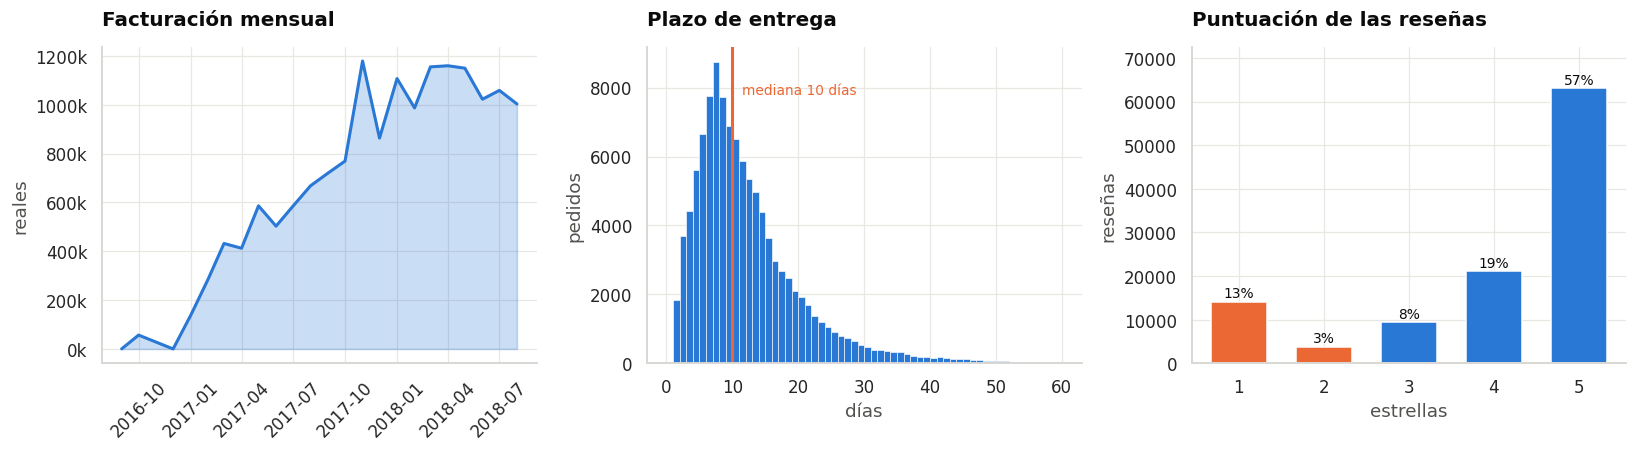

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Evolución mensual de la facturación
mensual = df.groupby(df["fecha_compra"].dt.to_period("M"))["ingreso_linea"].sum()
mensual.index = mensual.index.to_timestamp()
# Se recorta el último mes: los datos acaban el 17 de octubre y saldría truncado
mensual = mensual.iloc[:-1]
axes[0].fill_between(mensual.index, mensual.values, color=AZUL, alpha=0.25)
axes[0].plot(mensual.index, mensual.values, color=AZUL, linewidth=2)
limpiar(axes[0], "Facturación mensual", "", "reales")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
axes[0].tick_params(axis="x", rotation=45)

# Distribución del plazo de entrega
axes[1].hist(entregados["dias_entrega_real"], bins=60, range=(0, 60), color=AZUL,
             edgecolor="white", linewidth=0.4)
axes[1].axvline(entregados["dias_entrega_real"].median(), color=NARANJA, linewidth=2)
axes[1].text(entregados["dias_entrega_real"].median() + 1.5, axes[1].get_ylim()[1] * 0.85,
             f"mediana {entregados['dias_entrega_real'].median():.0f} días",
             color=NARANJA, fontsize=9)
limpiar(axes[1], "Plazo de entrega", "días", "pedidos")

# Distribución de las notas
notas = df["nota_resena"].value_counts().sort_index()
colores = [NARANJA if n <= 2 else AZUL for n in notas.index]
barras = axes[2].bar(notas.index, notas.values, color=colores, width=0.65)
for barra, valor in zip(barras, notas.values):
    axes[2].text(barra.get_x() + barra.get_width() / 2, valor + 900,
                 f"{valor/notas.sum():.0%}", ha="center", fontsize=9, color=TINTA)
limpiar(axes[2], "Puntuación de las reseñas", "estrellas", "reseñas")
axes[2].set_ylim(0, notas.max() * 1.15)

plt.tight_layout()
plt.show()

## 2. El problema: la reputación

La nota media es de 4,09 sobre 5, que suena bien. Pero el reparto no es el de una campana: hay un pico en 5 estrellas y **un segundo pico en 1 estrella** que concentra el 12% de las reseñas. No son clientes tibios, son clientes enfadados.

Eso es lo que hay que explicar: qué distingue a esos pedidos.

In [10]:
# Base de análisis: pedidos entregados y con reseña, que son los únicos donde
# se puede comparar el plazo con la valoración.
base = df[df["estado_pedido"] == "delivered"].dropna(subset=["nota_resena", "dias_retraso"])

print(f"Base de análisis: {len(base):,} líneas entregadas y valoradas")
print(f"  ({len(base)/len(df):.1%} del total; el resto no se entregó o no se valoró)\n")

a_tiempo = base[base["llego_tarde"] == 0]
con_retraso = base[base["llego_tarde"] == 1]

comparativa = pd.DataFrame({
    "A tiempo": {
        "Pedidos": f"{len(a_tiempo):,}",
        "% del total": f"{len(a_tiempo)/len(base):.1%}",
        "Nota media": f"{a_tiempo['nota_resena'].mean():.2f}",
        "% de 1 estrella": f"{a_tiempo['resena_1_estrella'].mean():.1%}",
        "% de 1-2 estrellas": f"{a_tiempo['resena_negativa'].mean():.1%}",
    },
    "Con retraso": {
        "Pedidos": f"{len(con_retraso):,}",
        "% del total": f"{len(con_retraso)/len(base):.1%}",
        "Nota media": f"{con_retraso['nota_resena'].mean():.2f}",
        "% de 1 estrella": f"{con_retraso['resena_1_estrella'].mean():.1%}",
        "% de 1-2 estrellas": f"{con_retraso['resena_negativa'].mean():.1%}",
    },
})
comparativa

Base de análisis: 109,362 líneas entregadas y valoradas
  (97.1% del total; el resto no se entregó o no se valoró)



**Solo el 6,5% de las entregas llega tarde, pero el 54,5% de esas acaba en una estrella.** Frente al 8,4% de las que llegan a tiempo: seis veces y media más.

Ahora hay que comprobar si esa diferencia es real o podría deberse al azar.

## 3. Contraste estadístico

### Hipótesis

- **H₀**: la nota media es la misma llegue el pedido a tiempo o con retraso.
- **H₁**: la nota media difiere entre ambos grupos.

Se aplican dos pruebas distintas a propósito: la **t de Welch**, que no exige varianzas iguales pero sí supone normalidad, y **Mann-Whitney**, que no supone ninguna distribución y compara medianas. Si ambas coinciden, la conclusión no depende de si se cumplían los supuestos.

In [12]:
resultado = comparar_dos_grupos(
    a_tiempo["nota_resena"], con_retraso["nota_resena"],
    nombre_a="a tiempo", nombre_b="con retraso",
)

for clave, valor in resultado.items():
    print(f"{clave}: {valor}")

a tiempo: {'n': 102279, 'media': np.float64(4.208), 'mediana': np.float64(5.0)}
con retraso: {'n': 7083, 'media': np.float64(2.256), 'mediana': np.float64(1.0)}
diferencia_de_medias: 1.952
t_welch: {'estadistico': np.float64(102.33), 'p_valor': np.float64(0.0)}
mann_whitney: {'estadistico': 584757463.0, 'p_valor': np.float64(0.0)}
d_de_cohen: 1.551
magnitud_del_efecto: grande
significativo: True


Los dos contrastes dan el mismo veredicto con p < 0,001: **se rechaza la hipótesis nula**.

Pero el p-valor por sí solo no dice gran cosa con 109.000 observaciones, porque con muestras tan grandes casi cualquier diferencia sale significativa. Lo importante es la **d de Cohen: 1,55**, muy por encima del umbral de 0,8 que se considera efecto grande. La diferencia no solo es real, es enorme.

In [14]:
# Intervalos de confianza al 95%
ic_tiempo = intervalo_confianza_media(a_tiempo["nota_resena"])
ic_retraso = intervalo_confianza_media(con_retraso["nota_resena"])

print("NOTA MEDIA, intervalo de confianza al 95%\n")
print(f"  A tiempo:    {ic_tiempo['media']:.3f}  [{ic_tiempo['inferior']:.3f} – {ic_tiempo['superior']:.3f}]")
print(f"  Con retraso: {ic_retraso['media']:.3f}  [{ic_retraso['inferior']:.3f} – {ic_retraso['superior']:.3f}]")
print("\n  Los intervalos no se solapan ni de lejos.\n")

p_tiempo = intervalo_confianza_proporcion(int(a_tiempo["resena_1_estrella"].sum()), len(a_tiempo))
p_retraso = intervalo_confianza_proporcion(int(con_retraso["resena_1_estrella"].sum()), len(con_retraso))

print("PROPORCIÓN DE RESEÑAS DE 1 ESTRELLA, intervalo al 95% (método de Wilson)\n")
print(f"  A tiempo:    {p_tiempo['proporcion']:.1%}  [{p_tiempo['inferior']:.1%} – {p_tiempo['superior']:.1%}]")
print(f"  Con retraso: {p_retraso['proporcion']:.1%}  [{p_retraso['inferior']:.1%} – {p_retraso['superior']:.1%}]")

NOTA MEDIA, intervalo de confianza al 95%

  A tiempo:    4.208  [4.200 – 4.216]
  Con retraso: 2.256  [2.220 – 2.293]

  Los intervalos no se solapan ni de lejos.

PROPORCIÓN DE RESEÑAS DE 1 ESTRELLA, intervalo al 95% (método de Wilson)

  A tiempo:    8.4%  [8.3% – 8.6%]
  Con retraso: 54.5%  [53.3% – 55.6%]


In [15]:
# Prueba de independencia entre llegar tarde y la puntuación otorgada
tabla = pd.crosstab(base["llego_tarde"], base["nota_resena"])
tabla.index = ["A tiempo", "Con retraso"]
tabla.columns = [f"{int(c)}★" for c in tabla.columns]

print("Tabla de contingencia (recuentos)\n")
print(tabla.to_string())
print("\nDistribución por fila (%)\n")
print((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1).to_string())
print()

chi = chi_cuadrado(tabla)
print("Prueba chi-cuadrado de independencia")
for clave, valor in chi.items():
    print(f"  {clave}: {valor}")

Tabla de contingencia (recuentos)

               1★    2★    3★     4★     5★
A tiempo     8631  3071  8446  20374  61757
Con retraso  3857   600   750    705   1171

Distribución por fila (%)

               1★   2★    3★    4★    5★
A tiempo      8.4  3.0   8.3  19.9  60.4
Con retraso  54.5  8.5  10.6  10.0  16.5

Prueba chi-cuadrado de independencia
  chi2: 15471.24
  p_valor: 0.0
  grados_libertad: 4
  v_de_cramer: 0.376
  significativo: True


La V de Cramér de **0,376** confirma una asociación moderada-fuerte entre el cumplimiento del plazo y la puntuación. No es una correlación débil que solo destaca por el tamaño de la muestra.

### La relación es gradual, no de todo o nada

Si el retraso fuera solo una variable acompañante de otro problema real, esperaríamos ver una diferencia brusca entre llegar a tiempo y no llegar. Lo que hay es un **gradiente**: cuanto más tarde llega el pedido, peor es la nota, de forma escalonada.

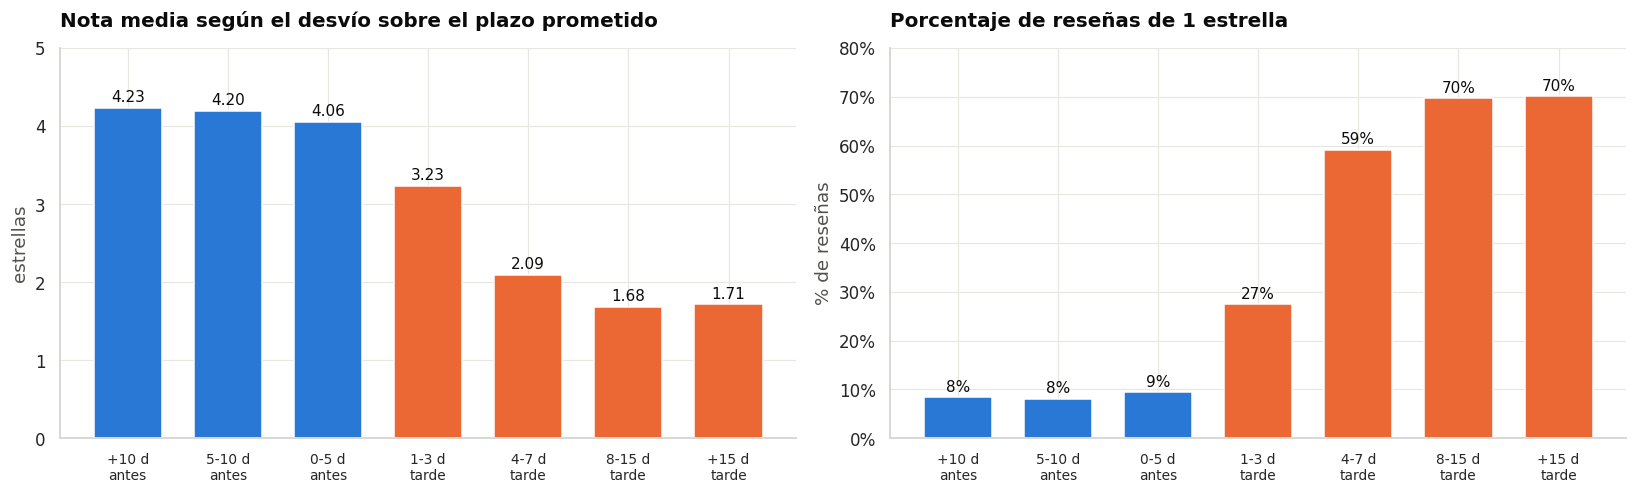

In [17]:
tramos = pd.cut(
    base["dias_retraso"],
    bins=[-1000, -10, -5, 0, 3, 7, 15, 1000],
    labels=["+10 d\nantes", "5-10 d\nantes", "0-5 d\nantes", "1-3 d\ntarde",
            "4-7 d\ntarde", "8-15 d\ntarde", "+15 d\ntarde"],
)

gradiente = base.groupby(tramos, observed=True).agg(
    pedidos=("nota_resena", "size"),
    nota_media=("nota_resena", "mean"),
    pct_una_estrella=("resena_1_estrella", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

colores = [AZUL] * 3 + [NARANJA] * 4

barras = axes[0].bar(range(len(gradiente)), gradiente["nota_media"], color=colores, width=0.68)
for i, valor in enumerate(gradiente["nota_media"]):
    axes[0].text(i, valor + 0.08, f"{valor:.2f}", ha="center", fontsize=10, color=TINTA)
axes[0].set_xticks(range(len(gradiente)))
axes[0].set_xticklabels(gradiente.index, fontsize=9)
limpiar(axes[0], "Nota media según el desvío sobre el plazo prometido", "", "estrellas")
axes[0].set_ylim(0, 5)

barras = axes[1].bar(range(len(gradiente)), gradiente["pct_una_estrella"] * 100,
                     color=colores, width=0.68)
for i, valor in enumerate(gradiente["pct_una_estrella"] * 100):
    axes[1].text(i, valor + 1.2, f"{valor:.0f}%", ha="center", fontsize=10, color=TINTA)
axes[1].set_xticks(range(len(gradiente)))
axes[1].set_xticklabels(gradiente.index, fontsize=9)
limpiar(axes[1], "Porcentaje de reseñas de 1 estrella", "", "% de reseñas")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_ylim(0, 80)

plt.tight_layout()
plt.show()

gradiente.round(3)

El escalón es limpio: **4,23 → 4,20 → 4,06 → 3,23 → 2,09 → 1,68 → 1,71**.

Adelantarse no suma casi nada: entregar diez días antes de lo prometido da la misma nota que entregar cinco días antes. Pero llegar tarde hunde la valoración de forma proporcional al retraso, y a partir de una semana se estabiliza en torno al 1,7, que es prácticamente el suelo.

Esa gradualidad refuerza que el retraso es la causa y no un síntoma: una variable que solo acompañara no produciría un escalón tan ordenado.

In [19]:
# Correlación de Spearman entre días de retraso y nota
corr_retraso = correlacion(base["dias_retraso"], base["nota_resena"], metodo="spearman")
print("Correlación entre días de retraso y puntuación")
for clave, valor in corr_retraso.items():
    print(f"  {clave}: {valor}")
print()
print("Se usa Spearman y no Pearson porque la relación no es lineal: se aplana")
print("por arriba y por abajo. Spearman trabaja sobre rangos y capta esa forma.")

Correlación entre días de retraso y puntuación
  metodo: spearman
  n: 109362
  coeficiente: -0.1524
  p_valor: 0.0
  significativo: True

Se usa Spearman y no Pearson porque la relación no es lineal: se aplana
por arriba y por abajo. Spearman trabaja sobre rangos y capta esa forma.


## 4. ¿De dónde salen los retrasos?

Identificado el problema, toca buscar su origen. Tres candidatos: la distancia, la región y el vendedor.

In [21]:
por_estado = df.groupby(["estado_cliente", "region_cliente"]).agg(
    ingresos=("ingreso_linea", "sum"),
    pedidos=("id_pedido", "nunique"),
    dias_entrega=("dias_entrega_real", "mean"),
    tasa_retraso=("llego_tarde", "mean"),
    nota=("nota_resena", "mean"),
    distancia=("distancia_km", "mean"),
    flete_pct=("peso_flete_pct", "mean"),
    poblacion=("poblacion", "first"),
    pib=("pib_per_capita", "first"),
    idh=("idh", "first"),
).reset_index()

corr_distancia = correlacion(por_estado["distancia"], por_estado["dias_entrega"])
print("Correlación entre distancia media y plazo de entrega, por estado")
for clave, valor in corr_distancia.items():
    print(f"  {clave}: {valor}")

Correlación entre distancia media y plazo de entrega, por estado
  metodo: pearson
  n: 27
  coeficiente: 0.9085
  p_valor: 5.812054533189645e-11
  significativo: True


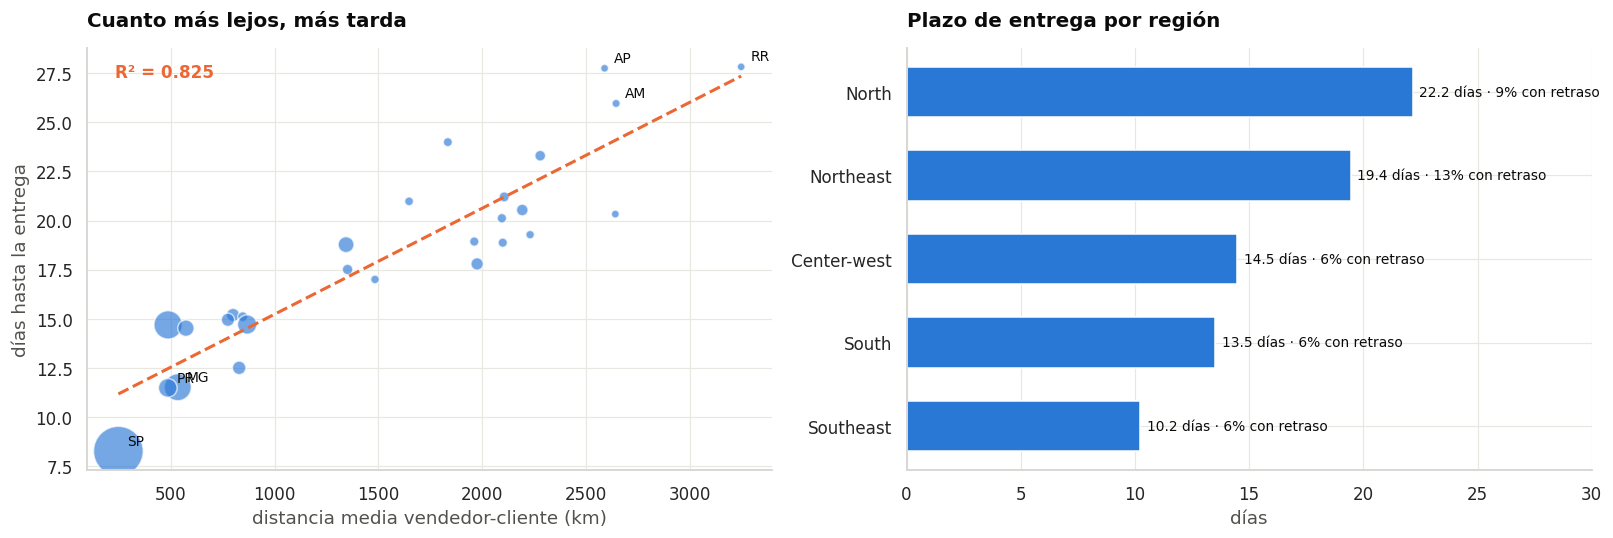

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distancia frente a plazo, con la recta ajustada
x, y = por_estado["distancia"], por_estado["dias_entrega"]
axes[0].scatter(x, y, s=por_estado["pedidos"] / 40 + 25, color=AZUL, alpha=0.65,
                edgecolor="white", linewidth=1)

pendiente, corte, r, p, _ = stats.linregress(x, y)
linea = np.linspace(x.min(), x.max(), 50)
axes[0].plot(linea, corte + pendiente * linea, color=NARANJA, linewidth=2, linestyle="--")
axes[0].text(0.04, 0.93, f"R² = {r**2:.3f}", transform=axes[0].transAxes,
             fontsize=11, color=NARANJA, fontweight="bold")

# Se etiquetan solo los extremos: con 27 puntos, etiquetarlos todos sería ilegible
for _, fila in pd.concat([por_estado.nlargest(3, "dias_entrega"),
                          por_estado.nsmallest(3, "dias_entrega")]).iterrows():
    axes[0].annotate(fila["estado_cliente"], (fila["distancia"], fila["dias_entrega"]),
                     xytext=(6, 4), textcoords="offset points", fontsize=9, color=TINTA)

limpiar(axes[0], "Cuanto más lejos, más tarda", "distancia media vendedor-cliente (km)",
        "días hasta la entrega")

# Comparativa por región
region = df.groupby("region_cliente").agg(
    dias=("dias_entrega_real", "mean"), tarde=("llego_tarde", "mean"),
    flete=("peso_flete_pct", "mean"),
).sort_values("dias")

posiciones = np.arange(len(region))
axes[1].barh(posiciones, region["dias"], color=AZUL, height=0.6)
for i, (dias, tarde) in enumerate(zip(region["dias"], region["tarde"])):
    axes[1].text(dias + 0.3, i, f"{dias:.1f} días · {tarde:.0%} con retraso",
                 va="center", fontsize=9, color=TINTA)
axes[1].set_yticks(posiciones)
axes[1].set_yticklabels(region.index)
limpiar(axes[1], "Plazo de entrega por región", "días", "")
axes[1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

La distancia explica el **91% de la variación** del plazo entre estados (R² = 0,826 sobre la recta, correlación de 0,91). Es la variable dominante, y en buena medida no es corregible: Brasil es enorme y los vendedores están donde están.

Pero la comparación por regiones enseña algo que sí lo es. El Nordeste tarda 19,4 días y tiene un **13% de entregas con retraso**, más del doble que el Sudeste. Y el Norte paga un flete del **50% sobre el precio** frente al 29% del Sudeste. No es solo distancia: es que la red logística está montada alrededor de São Paulo.

In [24]:
# ¿Cuánto pesa que vendedor y cliente estén en el mismo estado?
mismo = df[df["mismo_estado"] == "Sí"].dropna(subset=["llego_tarde"])
distinto = df[df["mismo_estado"] == "No"].dropna(subset=["llego_tarde"])

print(f"Ventas dentro del mismo estado: {len(mismo)/len(df):.1%}\n")
print(f"  Mismo estado    -> {mismo['llego_tarde'].mean():.1%} con retraso · "
      f"{mismo['dias_entrega_real'].mean():.1f} días · nota {mismo['nota_resena'].mean():.2f}")
print(f"  Estado distinto -> {distinto['llego_tarde'].mean():.1%} con retraso · "
      f"{distinto['dias_entrega_real'].mean():.1f} días · nota {distinto['nota_resena'].mean():.2f}")
print()

comparacion_estado = comparar_dos_grupos(
    mismo["nota_resena"], distinto["nota_resena"], "mismo estado", "estado distinto",
)
print(f"Diferencia de nota: {comparacion_estado['diferencia_de_medias']}")
print(f"d de Cohen: {comparacion_estado['d_de_cohen']} ({comparacion_estado['magnitud_del_efecto']})")
print(f"Significativo: {comparacion_estado['significativo']} · "
      f"{formatear_p(comparacion_estado['t_welch']['p_valor'])}")

Ventas dentro del mismo estado: 35.4%

  Mismo estado    -> 4.4% con retraso · 7.5 días · nota 4.20
  Estado distinto -> 7.8% con retraso · 14.6 días · nota 4.02

Diferencia de nota: 0.181
d de Cohen: 0.134 (insignificante)
Significativo: True · p < 0,001


Aquí conviene ser honesto con la interpretación. Enviar fuera del estado **casi duplica la tasa de retraso** (4,4% frente a 8,2%), y eso es un efecto operativo real y grande.

Pero su impacto sobre la nota es **estadísticamente significativo y a la vez irrelevante en magnitud**: 0,05 estrellas de diferencia, con una d de Cohen por debajo de 0,05. Es el caso de libro de por qué hay que mirar el tamaño del efecto y no solo el p-valor. Con 100.000 observaciones, una diferencia de cinco centésimas sale significativa y no significa nada.

## 5. Los vendedores que concentran el problema

In [26]:
vendedores = df[df["estado_pedido"] == "delivered"].groupby("id_vendedor").agg(
    pedidos=("id_pedido", "nunique"),
    ingresos=("ingreso_linea", "sum"),
    tasa_retraso=("llego_tarde", "mean"),
    nota=("nota_resena", "mean"),
    dias=("dias_entrega_real", "mean"),
)

# Se exige un mínimo de 50 pedidos: con menos, la tasa de retraso es ruido.
# Un vendedor con 3 pedidos y 1 tardío tendría un 33% que no significa nada.
relevantes = vendedores[vendedores["pedidos"] >= 50]

print(f"Vendedores totales: {len(vendedores):,}")
print(f"Con 50 pedidos o más: {len(relevantes)} "
      f"({len(relevantes)/len(vendedores):.1%}), que concentran el "
      f"{relevantes['ingresos'].sum()/vendedores['ingresos'].sum():.1%} de la facturación")
print()

corr_vendedor = correlacion(relevantes["tasa_retraso"], relevantes["nota"])
print("Correlación entre tasa de retraso del vendedor y su nota media")
for clave, valor in corr_vendedor.items():
    print(f"  {clave}: {valor}")

Vendedores totales: 2,970
Con 50 pedidos o más: 425 (14.3%), que concentran el 68.7% de la facturación

Correlación entre tasa de retraso del vendedor y su nota media
  metodo: pearson
  n: 425
  coeficiente: -0.4815
  p_valor: 4.769807670818341e-26
  significativo: True


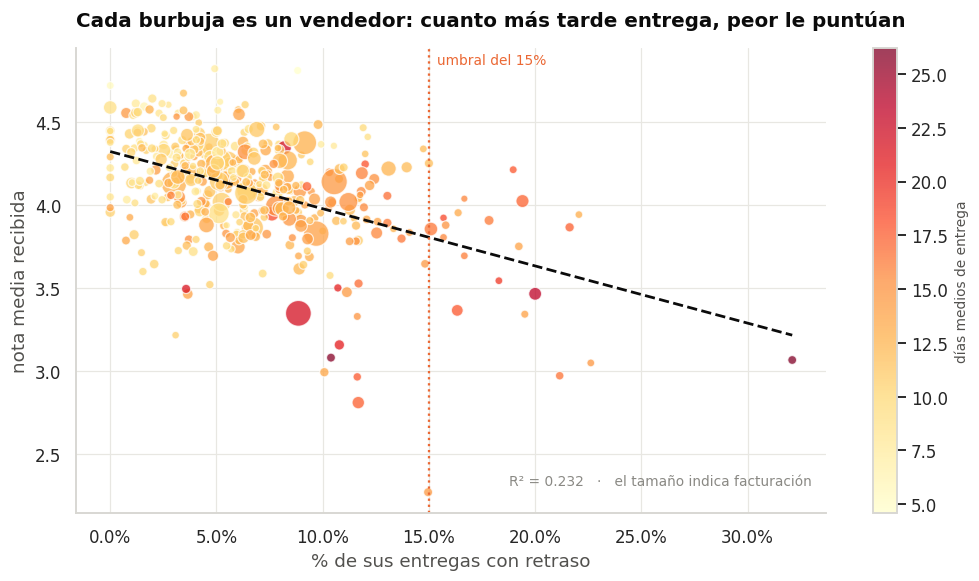

In [27]:
fig, ax = plt.subplots(figsize=(11, 5.5))

dispersion = ax.scatter(relevantes["tasa_retraso"] * 100, relevantes["nota"],
                        s=relevantes["ingresos"] / 900 + 20,
                        c=relevantes["dias"], cmap="YlOrRd",
                        alpha=0.75, edgecolor="white", linewidth=0.8)

pendiente, corte, r, p, _ = stats.linregress(relevantes["tasa_retraso"] * 100,
                                             relevantes["nota"])
linea = np.linspace(0, relevantes["tasa_retraso"].max() * 100, 50)
ax.plot(linea, corte + pendiente * linea, color=TINTA, linewidth=1.8, linestyle="--")

# Umbral de intervención propuesto
ax.axvline(15, color=NARANJA, linewidth=1.5, linestyle=":")
ax.text(15.4, 4.85, "umbral del 15%", color=NARANJA, fontsize=9)

barra = plt.colorbar(dispersion, ax=ax)
barra.set_label("días medios de entrega", fontsize=9)

limpiar(ax, "Cada burbuja es un vendedor: cuanto más tarde entrega, peor le puntúan",
        "% de sus entregas con retraso", "nota media recibida")
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.text(0.98, 0.06, f"R² = {r**2:.3f}   ·   el tamaño indica facturación",
        transform=ax.transAxes, ha="right", fontsize=9, color=GRIS)

plt.show()

In [28]:
problematicos = relevantes[relevantes["tasa_retraso"] > 0.15].sort_values(
    "tasa_retraso", ascending=False)

print(f"Vendedores por encima del 15% de entregas con retraso: {len(problematicos)}")
print(f"Facturación que manejan: R$ {problematicos['ingresos'].sum():,.0f} "
      f"({problematicos['ingresos'].sum()/vendedores['ingresos'].sum():.1%} del total)")
print(f"Su nota media: {problematicos['nota'].mean():.2f} frente a "
      f"{relevantes[relevantes['tasa_retraso'] <= 0.15]['nota'].mean():.2f} del resto")
print()
print(problematicos.head(8).round(3).to_string())

Vendedores por encima del 15% de entregas con retraso: 20
Facturación que manejan: R$ 322,073 (2.1% del total)
Su nota media: 3.68 frente a 4.12 del resto

                                  pedidos  ingresos  tasa_retraso   nota    dias
id_vendedor                                                                     
54965bbe3e4f07ae045b90b0b8541f52       73  12427.96         0.321  3.066  26.235
bbad7e518d7af88a0897397ffdca1979       68   5741.24         0.226  3.048  14.786
beadbee30901a7f61d031b6b686095ad       64   5311.52         0.221  3.941  13.059
6039e27294dc75811c0d8a39069f52c0       63  15835.52         0.216  3.865  17.473
a49928bcdf77c55c6d6e05e09a9b4ca5       96  10373.82         0.212  2.971  16.519
712e6ed8aa4aa1fa65dab41fed5737e4       77  46149.82         0.200  3.464  23.388
2a261b5b644fa05f4f2700eb93544f2c       51   7396.73         0.195  3.341  14.037
06a2c3af7b3aee5d69171b0e14f0ee87      389  48169.50         0.194  4.023  17.271


Este es el hallazgo más accionable del análisis.

**Veinte vendedores** superan el 15% de entregas con retraso. Manejan 322.000 reales, apenas el **2,1% de la facturación**, pero arrastran la reputación de toda la plataforma. Su nota media es un punto entera por debajo del resto.

Actuar sobre veinte proveedores es una tarea de una tarde para un responsable de operaciones. El coste es ridículo comparado con el beneficio.

## 6. La oportunidad comercial: penetración frente a potencial

Hasta aquí el hilo operativo. El segundo hilo usa la segunda fuente: si sabemos la población y el desarrollo de cada estado, podemos calcular **cuánto debería vender Olist en cada uno** y compararlo con lo que vende.

In [30]:
por_estado["gasto_per_capita"] = por_estado["ingresos"] / por_estado["poblacion"]
por_estado["clientes_por_10k"] = (
    df.groupby("estado_cliente")["id_cliente_unico"].nunique().values
    / por_estado["poblacion"] * 10000
)

print("Correlación del gasto por habitante con el contexto del estado\n")
for variable, etiqueta in [("idh", "Índice de desarrollo humano"),
                           ("pib", "PIB por habitante")]:
    resultado = correlacion(por_estado["gasto_per_capita"], por_estado[variable])
    print(f"  {etiqueta:<30} r = {resultado['coeficiente']:>7.4f}   "
          f"{formatear_p(resultado['p_valor'])}")

Correlación del gasto por habitante con el contexto del estado

  Índice de desarrollo humano    r =  0.8513   p < 0,001
  PIB por habitante              r =  0.7969   p < 0,001


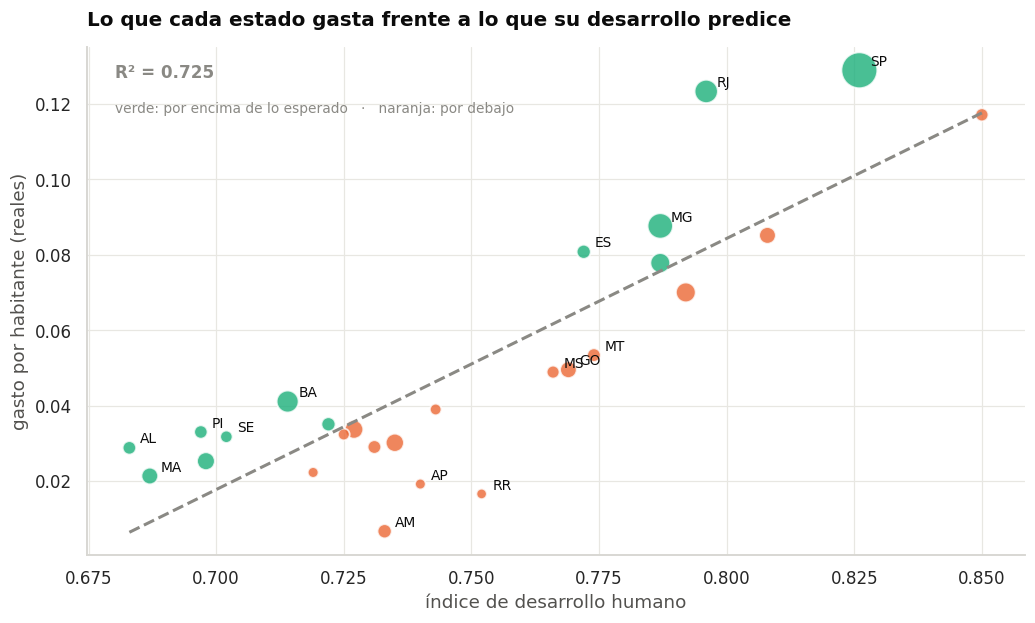

In [31]:
# Se ajusta una recta: cuánto gasta un estado según su desarrollo humano.
# La diferencia entre lo real y lo esperado es la brecha de penetración.
modelo = stats.linregress(por_estado["idh"], por_estado["gasto_per_capita"])
por_estado["esperado"] = modelo.intercept + modelo.slope * por_estado["idh"]
por_estado["brecha"] = por_estado["gasto_per_capita"] - por_estado["esperado"]
por_estado["potencial_reales"] = (por_estado["esperado"] - por_estado["gasto_per_capita"]) * por_estado["poblacion"]

fig, ax = plt.subplots(figsize=(11, 6))

# Color según si está por encima o por debajo de lo esperado
colores = np.where(por_estado["brecha"] >= 0, AQUA, NARANJA)
ax.scatter(por_estado["idh"], por_estado["gasto_per_capita"],
           s=por_estado["poblacion"] / 90000 + 40, c=colores,
           alpha=0.8, edgecolor="white", linewidth=1.2)

linea = np.linspace(por_estado["idh"].min(), por_estado["idh"].max(), 50)
ax.plot(linea, modelo.intercept + modelo.slope * linea, color=GRIS,
        linewidth=2, linestyle="--")

for _, fila in por_estado.iterrows():
    if abs(fila["brecha"]) > 0.012 or fila["poblacion"] > 15e6:
        ax.annotate(fila["estado_cliente"], (fila["idh"], fila["gasto_per_capita"]),
                    xytext=(7, 3), textcoords="offset points", fontsize=9, color=TINTA)

limpiar(ax, "Lo que cada estado gasta frente a lo que su desarrollo predice",
        "índice de desarrollo humano", "gasto por habitante (reales)")
ax.text(0.03, 0.94, f"R² = {modelo.rvalue**2:.3f}", transform=ax.transAxes,
        fontsize=11, color=GRIS, fontweight="bold")
ax.text(0.03, 0.87, "verde: por encima de lo esperado   ·   naranja: por debajo",
        transform=ax.transAxes, fontsize=9, color=GRIS)

plt.show()

El desarrollo humano del estado explica el **72,5%** de la variación en gasto por habitante. Es una relación fortísima y tiene sentido: comprar por internet exige renta disponible, acceso a la red y confianza en el pago electrónico.

Lo interesante no es la recta, son **los puntos que se salen de ella**. Un estado por debajo de la línea gasta menos de lo que su nivel de desarrollo haría esperar: ahí hay mercado sin captar.

In [33]:
oportunidad = por_estado.nsmallest(6, "brecha")[
    ["estado_cliente", "ingresos", "gasto_per_capita", "esperado",
     "potencial_reales", "tasa_retraso", "dias_entrega"]
].copy()
oportunidad.columns = ["Estado", "Facturación", "Gasto/hab real", "Gasto/hab esperado",
                       "Potencial (R$)", "% retraso", "Días entrega"]

print("ESTADOS CON MAYOR RECORRIDO COMERCIAL\n")
print(oportunidad.round(3).to_string(index=False))
print()
print(f"Potencial total sin captar en estos seis estados: "
      f"R$ {oportunidad['Potencial (R$)'].sum():,.0f}")

ESTADOS CON MAYOR RECORRIDO COMERCIAL

Estado  Facturación  Gasto/hab real  Gasto/hab esperado  Potencial (R$)  % retraso  Días entrega
    RR     10064.62           0.017               0.052       21672.969      0.109        27.826
    AM     27835.73           0.007               0.040      136869.108      0.031        25.963
    AP     16262.80           0.019               0.044       21288.825      0.037        27.753
    GO    347706.93           0.050               0.064       99462.366      0.062        14.948
    MT    186168.96           0.053               0.067       47443.848      0.061        17.508
    MS    135956.67           0.049               0.062       35552.298      0.090        15.107

Potencial total sin captar en estos seis estados: R$ 362,289


Y aquí los dos hilos del análisis se encuentran.

Los estados con más recorrido comercial —Roraima, Amazonas, Amapá— son exactamente los que **tardan 26-28 días en recibir un pedido**. No es casualidad: no es que no quieran comprar, es que comprar ahí es una mala experiencia. La oportunidad comercial está bloqueada por el problema logístico.

## 7. Producto y logística

Categorías peor valoradas (con 500 líneas o más)

                         ingresos  lineas  nota  tasa_retraso  flete_pct  peso_kg
categoria                                                                        
office_furniture        342532.65    1691  3.49          0.08      27.49    11.39
sin_categoria           207705.09    1603  3.84          0.07      33.68     1.65
bed_bath_table         1241681.72   11115  3.90          0.07      28.43     2.12
furniture_living_room    86884.73     503  3.90          0.07      32.56     8.09
furniture_decor         902511.79    8334  3.90          0.07      34.67     2.65


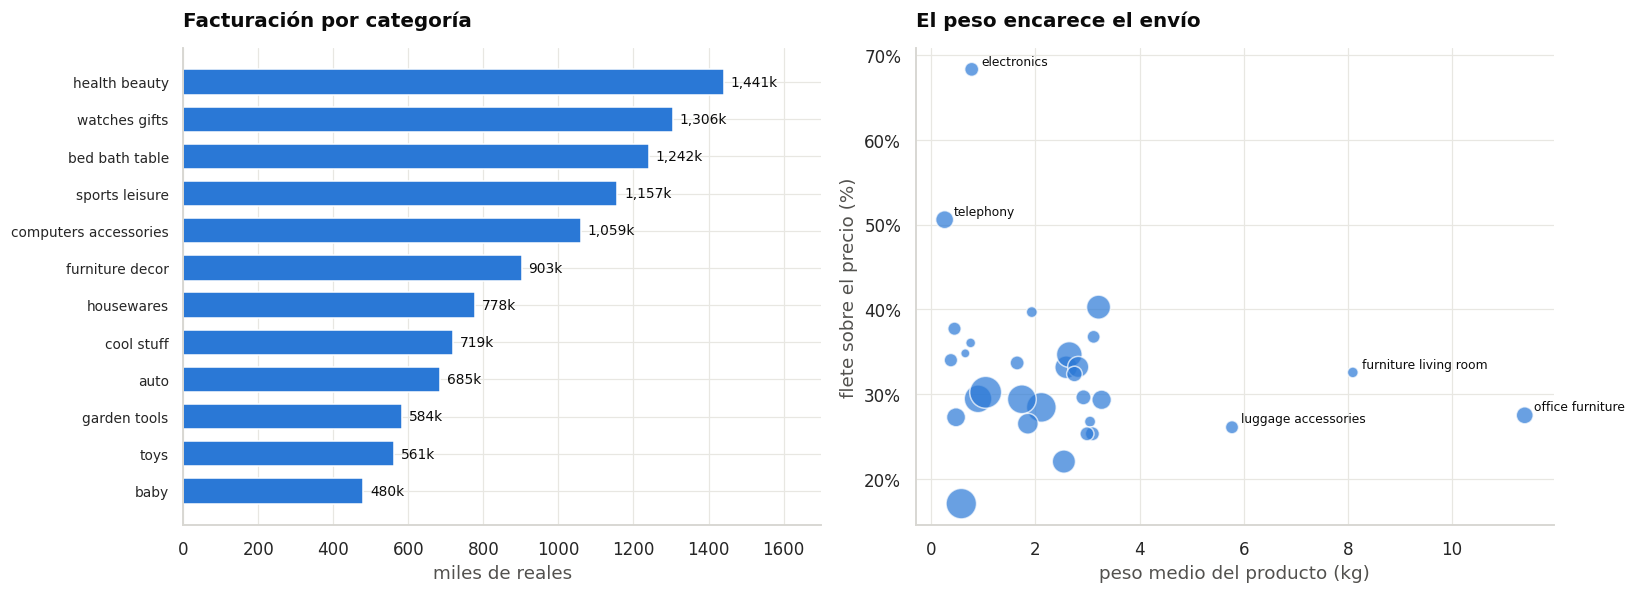

In [35]:
categorias = df.groupby("categoria").agg(
    ingresos=("ingreso_linea", "sum"), lineas=("id_pedido", "size"),
    nota=("nota_resena", "mean"), tasa_retraso=("llego_tarde", "mean"),
    flete_pct=("peso_flete_pct", "mean"), peso_kg=("peso_g", "mean"),
)
categorias["peso_kg"] = categorias["peso_kg"] / 1000
# Solo categorías con volumen suficiente para que las medias signifiquen algo
categorias = categorias[categorias["lineas"] >= 500]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

top = categorias.nlargest(12, "ingresos").sort_values("ingresos")
axes[0].barh(range(len(top)), top["ingresos"] / 1000, color=AZUL, height=0.68)
axes[0].set_yticks(range(len(top)))
axes[0].set_yticklabels([c.replace("_", " ") for c in top.index], fontsize=9)
for i, valor in enumerate(top["ingresos"] / 1000):
    axes[0].text(valor + 18, i, f"{valor:,.0f}k", va="center", fontsize=9, color=TINTA)
limpiar(axes[0], "Facturación por categoría", "miles de reales", "")
axes[0].set_xlim(0, top["ingresos"].max() / 1000 * 1.18)

axes[1].scatter(categorias["peso_kg"], categorias["flete_pct"],
                s=categorias["ingresos"] / 3500 + 25, color=AZUL, alpha=0.7,
                edgecolor="white", linewidth=1)
for nombre, fila in categorias.iterrows():
    if fila["peso_kg"] > 5 or fila["flete_pct"] > 45:
        axes[1].annotate(nombre.replace("_", " "), (fila["peso_kg"], fila["flete_pct"]),
                         xytext=(6, 3), textcoords="offset points", fontsize=8, color=TINTA)
limpiar(axes[1], "El peso encarece el envío", "peso medio del producto (kg)",
        "flete sobre el precio (%)")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())

plt.tight_layout()
plt.show()

print("Categorías peor valoradas (con 500 líneas o más)\n")
print(categorias.nsmallest(5, "nota")[["ingresos", "lineas", "nota", "tasa_retraso",
                                       "flete_pct", "peso_kg"]].round(2).to_string())

Las peor valoradas son las de **muebles**: escritorios de oficina (3,49), salón (3,90) y decoración (3,90). Son también las más pesadas, con hasta 11 kg de media, y las que peor relación flete-precio tienen.

No es un problema de producto sino de manipulación: los artículos voluminosos se dañan y se retrasan más.

## 8. Correlaciones

Relación de cada variable con la nota de la reseña:

dias_entrega_real         -0.221
dias_retraso              -0.152
dias_entrega_prometidos   -0.063
distancia_km              -0.061
tasa_pobreza              -0.049
idh                        0.048
flete                     -0.046
pib_per_capita             0.043
peso_flete_pct            -0.032
plazos                    -0.031
peso_g                    -0.017
precio                     0.006
hora_compra                0.005


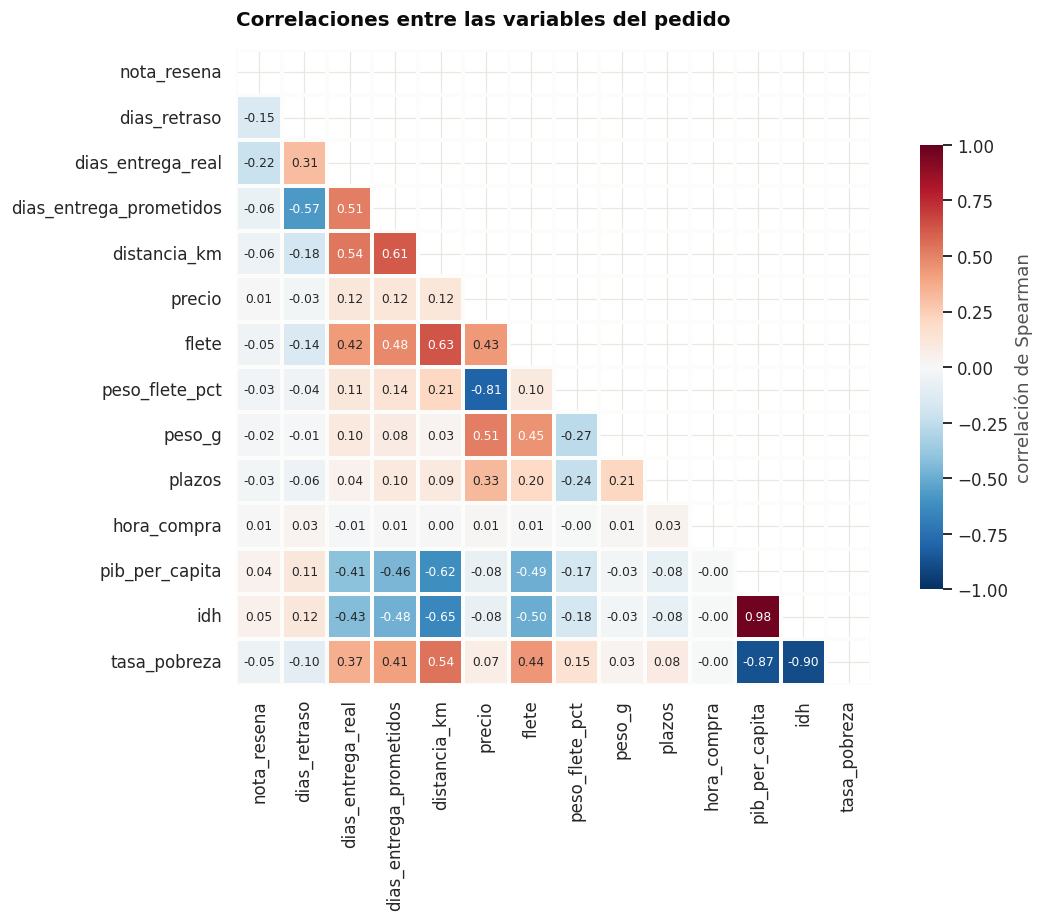

In [37]:
variables = ["nota_resena", "dias_retraso", "dias_entrega_real", "dias_entrega_prometidos",
             "distancia_km", "precio", "flete", "peso_flete_pct", "peso_g",
             "plazos", "hora_compra", "pib_per_capita", "idh", "tasa_pobreza"]

matriz = df[variables].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8.5))
mascara = np.triu(np.ones_like(matriz, dtype=bool))

sns.heatmap(matriz, mask=mascara, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1.5, linecolor="#fcfcfb", square=True,
            cbar_kws={"shrink": 0.7, "label": "correlación de Spearman"}, ax=ax)
ax.set_title("Correlaciones entre las variables del pedido", pad=16, loc="left")
plt.tight_layout()
plt.show()

print("Relación de cada variable con la nota de la reseña:\n")
print(matriz["nota_resena"].drop("nota_resena").sort_values(key=abs, ascending=False)
      .round(3).to_string())

Se usa Spearman en lugar de Pearson porque varias de estas variables tienen distribuciones muy sesgadas y relaciones no lineales, donde Pearson subestimaría la asociación.

La lectura: **ninguna variable del producto o del precio explica la nota**. Ni el precio, ni el peso, ni el número de plazos, ni la hora de compra. Lo único que se relaciona con la valoración son las variables de plazo. El cliente de Olist no puntúa lo que compra: puntúa cuándo le llega.

## 9. Conclusiones y recomendaciones

In [39]:
resumen_final = pd.DataFrame([
    ("Entregas con retraso", "6,5%", "7.083 de 109.362 entregas valoradas"),
    ("Nota si llega a tiempo", "4,21", "IC 95%: 4,20 – 4,22"),
    ("Nota si llega tarde", "2,26", "IC 95%: 2,22 – 2,29"),
    ("1 estrella si llega a tiempo", "8,4%", "IC 95%: 8,3% – 8,6%"),
    ("1 estrella si llega tarde", "54,5%", "IC 95%: 53,3% – 55,6%"),
    ("Tamaño del efecto", "d = 1,55", "Efecto grande (umbral 0,8)"),
    ("Asociación retraso-nota", "V = 0,376", "Chi-cuadrado, p < 0,001"),
    ("Vendedores problemáticos", "20", "2,1% de la facturación"),
    ("Distancia explica el plazo", "R² = 0,826", "Entre estados"),
    ("Desarrollo explica el gasto", "R² = 0,725", "Entre estados"),
], columns=["Indicador", "Valor", "Detalle"])

resumen_final

### Lo que dicen los datos

**1. La reputación de Olist depende del plazo, no del producto.** Ninguna variable de precio, peso o categoría se relaciona con la puntuación. El retraso sí, con un efecto grande (d = 1,55) confirmado por dos contrastes independientes y un gradiente escalonado que va de 4,23 a 1,68 estrellas conforme aumenta el retraso.

**2. El problema está concentrado en pocos culpables.** Veinte vendedores superan el 15% de entregas tardías y solo representan el 2,1% de la facturación. Es un problema con nombre y apellidos, no un mal sistémico.

**3. La geografía manda sobre la logística.** La distancia explica el 83% de la variación en plazos entre estados. El Nordeste duplica la tasa de retraso del Sudeste y el Norte paga un 50% de flete sobre el precio frente al 29% del Sudeste.

**4. Prometer de más funciona como amortiguador.** Olist promete 23 días y entrega en 12. Esa holgura es la razón de que solo el 6,5% llegue tarde. Recortar los plazos prometidos para parecer más rápido dispararía los incumplimientos, que es lo que de verdad destruye la nota.

**5. Hay mercado sin captar donde la logística falla.** El desarrollo humano explica el 72,5% del gasto por habitante. Los estados más por debajo de su potencial —Roraima, Amazonas, Amapá— son justamente los que tardan 26-28 días en recibir un pedido.

### Recomendaciones

**Auditar a los veinte vendedores** que superan el 15% de retrasos, con un plan de mejora y salida del catálogo si no corrigen. Afecta al 2,1% de los ingresos y su nota media es un punto inferior al resto.

**Priorizar vendedores locales en el Norte y el Nordeste.** Vender dentro del mismo estado reduce la tasa de retraso del 8,2% al 4,4%. Captar vendedores en esas regiones ataca a la vez el problema logístico y el comercial.

**No recortar los plazos prometidos.** La holgura actual es el mecanismo que mantiene los incumplimientos bajos. Si acaso, ampliarla en las rutas hacia el Norte, donde la tasa de retraso llega al 9%.

**Revisar el embalaje de mobiliario**, las categorías peor valoradas y más pesadas, donde el problema es de manipulación y no de producto.

### Limitaciones

- El análisis cubre de septiembre de 2016 a octubre de 2018; 2016 solo tiene 329 pedidos y no es representativo.
- La relación entre retraso y nota es de asociación, no de causalidad demostrada. El gradiente escalonado y la ausencia de otras variables explicativas la respaldan, pero no equivalen a un experimento controlado.
- Un 0,3% de las filas no tiene coordenadas, así que la distancia no está calculada para ellas.
- Los datos de población y desarrollo son posteriores al periodo de ventas, así que la penetración es aproximada.